In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib.cm as cm
import plotly.express as px

In [13]:
def sample_cohort(group, n=10000):
    if len(group) > n:
        return group.sample(n=n, random_state=42)
    else:
        return group

# SAM-Med3D

In [14]:
df = pd.read_csv("../../local/output/combined_data_sammed.csv")
df_params = pd.read_csv("../../local/input/all_img_params.csv")
print(len(df), len(df_params))

2644 3042


In [15]:
df = pd.merge(df, df_params, left_on='id', right_on='id', how='inner')
print(len(df))

2473


In [16]:
feature_cols = [f"Feature{i}" for i in range(1, 385)]
label_col = 'label'
cohort_col = 'cohort'
scanner_col = 'scanner'
mfs_col = 'MagneticFieldStrength'

In [17]:
df_sampled = df.groupby(cohort_col, group_keys=False).apply(sample_cohort)
X = df_sampled[feature_cols].values

/tmp/ipykernel_282690/1423725872.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sampled = df.groupby(cohort_col, group_keys=False).apply(sample_cohort)


In [18]:
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

In [19]:
df_sampled['tsne-1'] = X_tsne[:,0]
df_sampled['tsne-2'] = X_tsne[:,1]

/tmp/ipykernel_282690/753950695.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('Dark2')


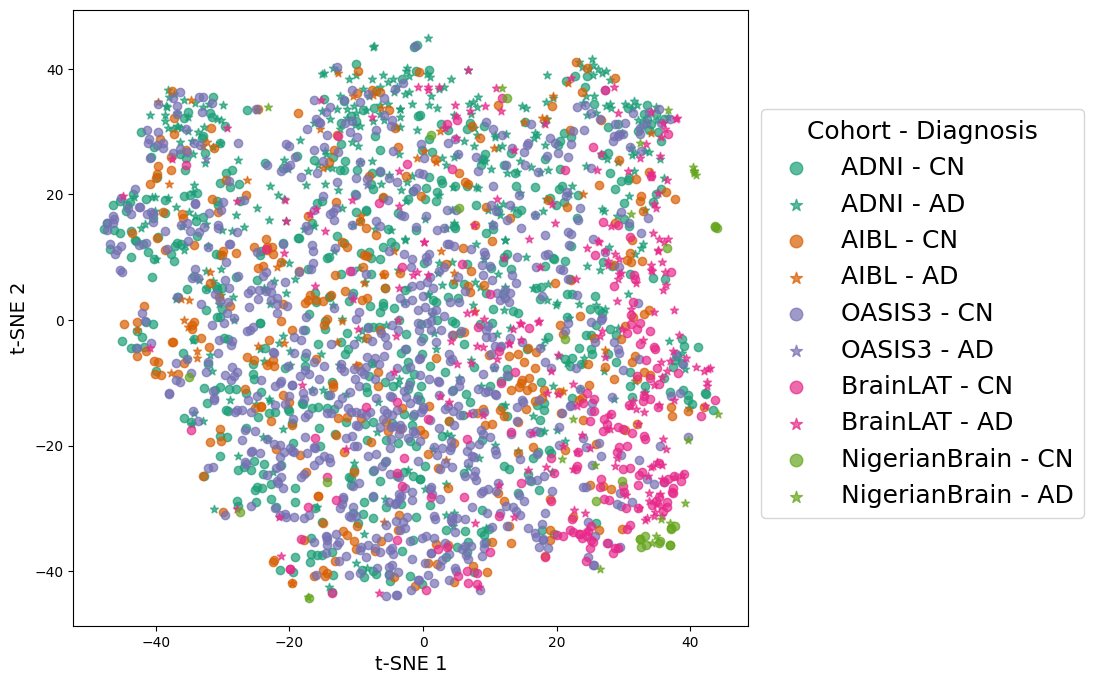

In [20]:
# ---------------------------
# Plot
# ---------------------------
cohorts = df_sampled[cohort_col].unique()
labels = df_sampled[label_col].unique()
markers = {0: 'o', 1: '*'}  # CN: circle, AD: star

colors = cm.get_cmap('Dark2')
cohort_color = {cohort: colors(i) for i, cohort in enumerate(cohorts)}

# Create a figure + single axes with fixed size
fig, ax = plt.subplots(figsize=(10, 8))

for cohort in cohorts:
    for label in labels:
        subset = df_sampled[
            (df_sampled[cohort_col] == cohort) &
            (df_sampled[label_col] == label)
        ]
        ax.scatter(
            subset['tsne-1'], subset['tsne-2'],
            color=cohort_color[cohort],
            marker=markers[label],
            alpha=0.7,
            label=f"{cohort} - {'AD' if label == 1 else 'CN'}"
        )

# Remove duplicates
handles, labels_text = ax.get_legend_handles_labels()
unique = dict(zip(labels_text, handles))

# Create legend at figure level (NOT inside axes)
fig.legend(
    unique.values(), unique.keys(),
    bbox_to_anchor=(0.8, 0.5),
    loc='center left',
    fontsize=18,
    title='Cohort - Diagnosis',
    title_fontsize=18,
    markerscale=1.5
)

ax.set_xlabel("t-SNE 1", fontsize=14)
ax.set_ylabel("t-SNE 2", fontsize=14)

# Prevent the legend from changing axes size
plt.subplots_adjust(right=0.8)

# plt.savefig("tsne_sammed_cohorts_labels.png", dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_282690/3125882918.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('Dark2')


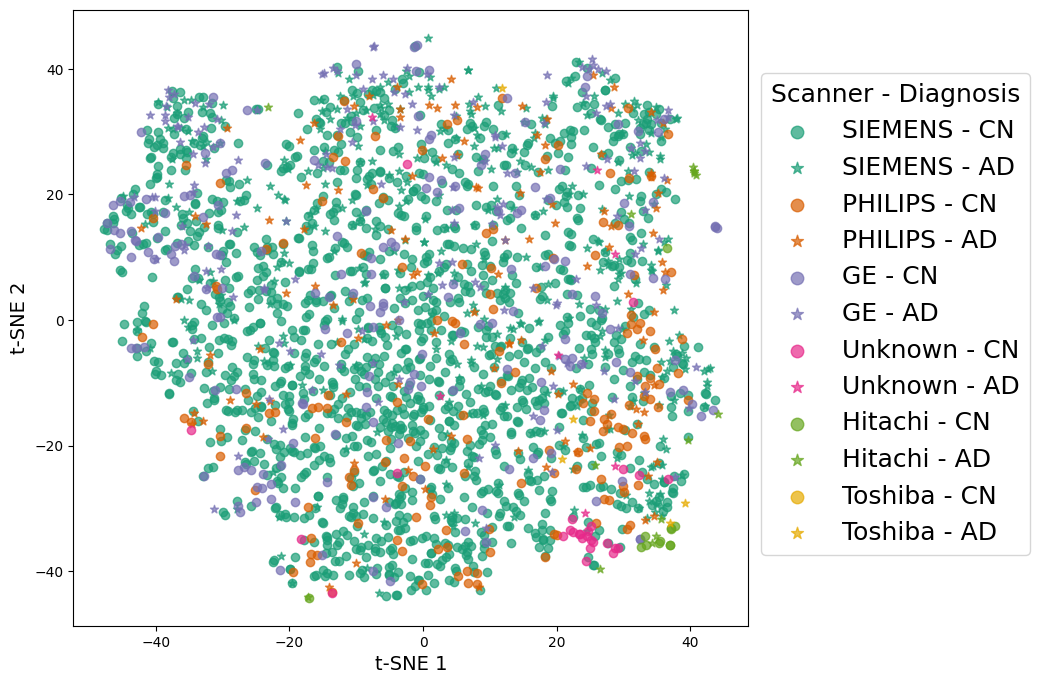

In [ ]:
# ---------------------------
# Plot
# ---------------------------
scanners = df_sampled[scanner_col].unique()
labels = df_sampled[label_col].unique()
markers = {0: 'o', 1: '*'}  # CN: circle, AD: star

colors = cm.get_cmap('Dark2')
scanner_color = {scanner: colors(i) for i, scanner in enumerate(scanners)}

# Create a figure + single axes with fixed size
fig, ax = plt.subplots(figsize=(10, 8))

for scanner in scanners:
    for label in labels:
        subset = df_sampled[
            (df_sampled[scanner_col] == scanner) &
            (df_sampled[label_col] == label)
        ]
        ax.scatter(
            subset['tsne-1'], subset['tsne-2'],
            color=scanner_color[scanner],
            marker=markers[label],
            alpha=0.7,
            label=f"{scanner} - {'AD' if label == 1 else 'CN'}"
        )

# Remove duplicates
handles, labels_text = ax.get_legend_handles_labels()
unique = dict(zip(labels_text, handles))

# Create legend at figure level (NOT inside axes)
fig.legend(
    unique.values(), unique.keys(),
    bbox_to_anchor=(0.8, 0.5),
    title='Scanner - Diagnosis',
    title_fontsize=18,
    loc='center left',
    fontsize=18,
    markerscale=1.5
)

ax.set_xlabel("t-SNE 1", fontsize=14)
ax.set_ylabel("t-SNE 2", fontsize=14)

# Prevent the legend from changing axes size
plt.subplots_adjust(right=0.8)

# plt.savefig("tsne_sammed_scanners_labels.png", dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_282690/975967342.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('Dark2')


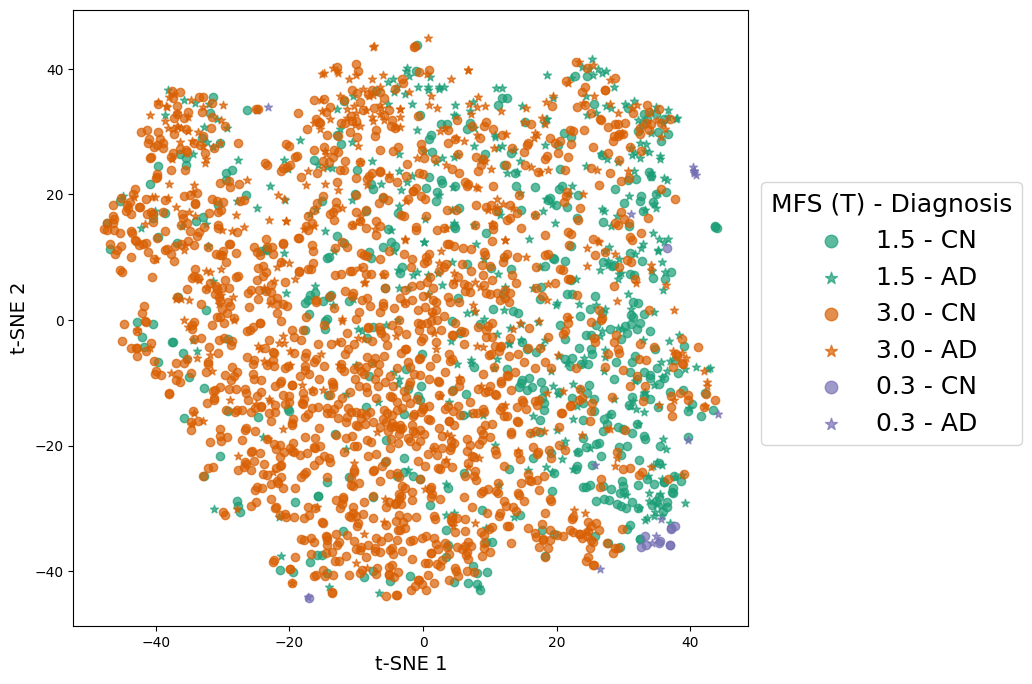

In [22]:
# ---------------------------
# Plot
# ---------------------------
mfs = df_sampled[mfs_col].unique()
labels = df_sampled[label_col].unique()
markers = {0: 'o', 1: '*'}  # CN: circle, AD: star

colors = cm.get_cmap('Dark2')
mfs_color = {mf: colors(i) for i, mf in enumerate(mfs)}

# Create a figure + single axes with fixed size
fig, ax = plt.subplots(figsize=(10, 8))

for mf in mfs:
    for label in labels:
        subset = df_sampled[
            (df_sampled[mfs_col] == mf) &
            (df_sampled[label_col] == label)
        ]
        ax.scatter(
            subset['tsne-1'], subset['tsne-2'],
            color=mfs_color[mf],
            marker=markers[label],
            alpha=0.7,
            label=f"{mf} - {'AD' if label == 1 else 'CN'}"
        )

# Remove duplicates
handles, labels_text = ax.get_legend_handles_labels()
unique = dict(zip(labels_text, handles))

# Create legend at figure level (NOT inside axes)
fig.legend(
    unique.values(), unique.keys(),
    bbox_to_anchor=(0.8, 0.5),
    title='MFS (T) - Diagnosis',
    title_fontsize=18,
    loc='center left',
    fontsize=18,
    markerscale=1.5
)

ax.set_xlabel("t-SNE 1", fontsize=14)
ax.set_ylabel("t-SNE 2", fontsize=14)

# Prevent the legend from changing axes size
plt.subplots_adjust(right=0.8)

# plt.savefig("tsne_sammed_mfs_labels.png", dpi=300, bbox_inches='tight')
plt.show()


# BrainIAC

In [23]:
df = pd.read_csv("../../local/output/combined_data_brainiac.csv")
df_params = pd.read_csv("../../local/input/all_img_params.csv")
print(len(df), len(df_params))

2644 3042


In [24]:
df = pd.merge(df, df_params, left_on='id', right_on='id', how='inner')
print(len(df))

2473


In [25]:
feature_cols = [f"Feature{i}" for i in range(1, 768)]
label_col = 'label'
cohort_col = 'cohort'
scanner_col = 'scanner'
mfs_col = 'MagneticFieldStrength'

In [26]:
df_sampled = df.groupby(cohort_col, group_keys=False).apply(sample_cohort)
X = df_sampled[feature_cols].values

/tmp/ipykernel_282690/1423725872.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sampled = df.groupby(cohort_col, group_keys=False).apply(sample_cohort)


In [27]:
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

In [28]:
df_sampled['tsne-1'] = X_tsne[:,0]
df_sampled['tsne-2'] = X_tsne[:,1]

/tmp/ipykernel_282690/4144416011.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('Dark2')


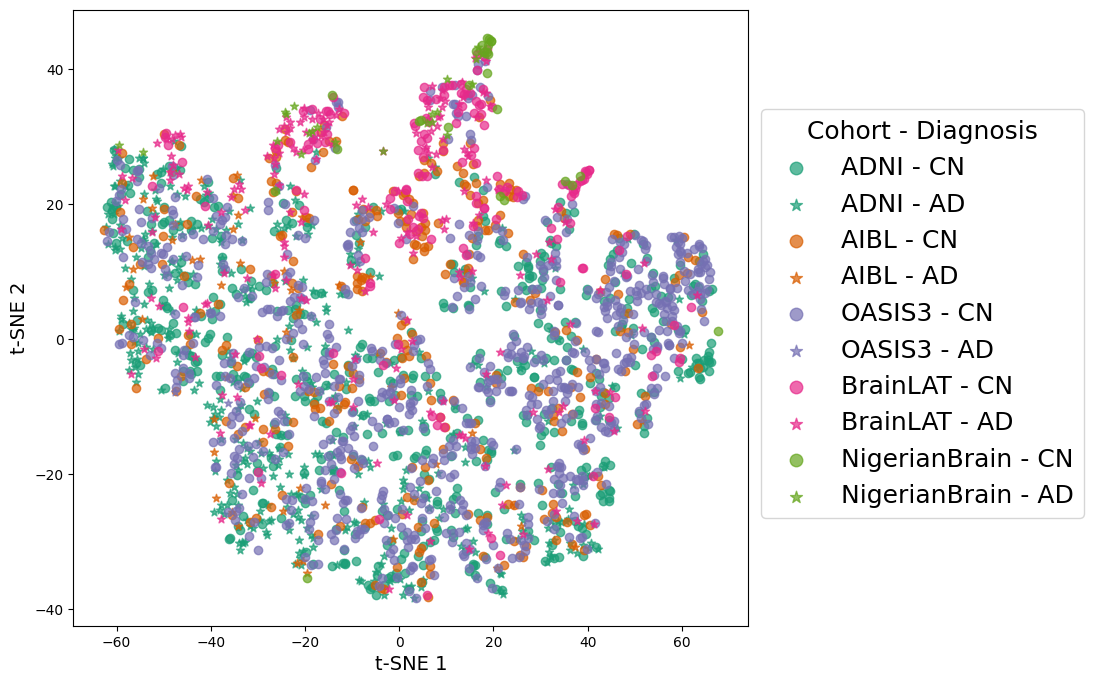

In [29]:
# ---------------------------
# Plot
# ---------------------------
cohorts = df_sampled[cohort_col].unique()
labels = df_sampled[label_col].unique()
markers = {0: 'o', 1: '*'}  # CN: circle, AD: star

colors = cm.get_cmap('Dark2')
cohort_color = {cohort: colors(i) for i, cohort in enumerate(cohorts)}

# Create a figure + single axes with fixed size
fig, ax = plt.subplots(figsize=(10, 8))

for cohort in cohorts:
    for label in labels:
        subset = df_sampled[
            (df_sampled[cohort_col] == cohort) &
            (df_sampled[label_col] == label)
        ]
        ax.scatter(
            subset['tsne-1'], subset['tsne-2'],
            color=cohort_color[cohort],
            marker=markers[label],
            alpha=0.7,
            label=f"{cohort} - {'AD' if label == 1 else 'CN'}"
        )

# Remove duplicates
handles, labels_text = ax.get_legend_handles_labels()
unique = dict(zip(labels_text, handles))

# Create legend at figure level (NOT inside axes)
fig.legend(
    unique.values(), unique.keys(),
    bbox_to_anchor=(0.8, 0.5),
    loc='center left',
    fontsize=18,
    title='Cohort - Diagnosis',
    title_fontsize=18,
    markerscale=1.5
)

ax.set_xlabel("t-SNE 1", fontsize=14)
ax.set_ylabel("t-SNE 2", fontsize=14)

# Prevent the legend from changing axes size
plt.subplots_adjust(right=0.8)

# plt.savefig("tsne_brainiac_cohorts_labels.png", dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_282690/2518262434.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('Dark2')


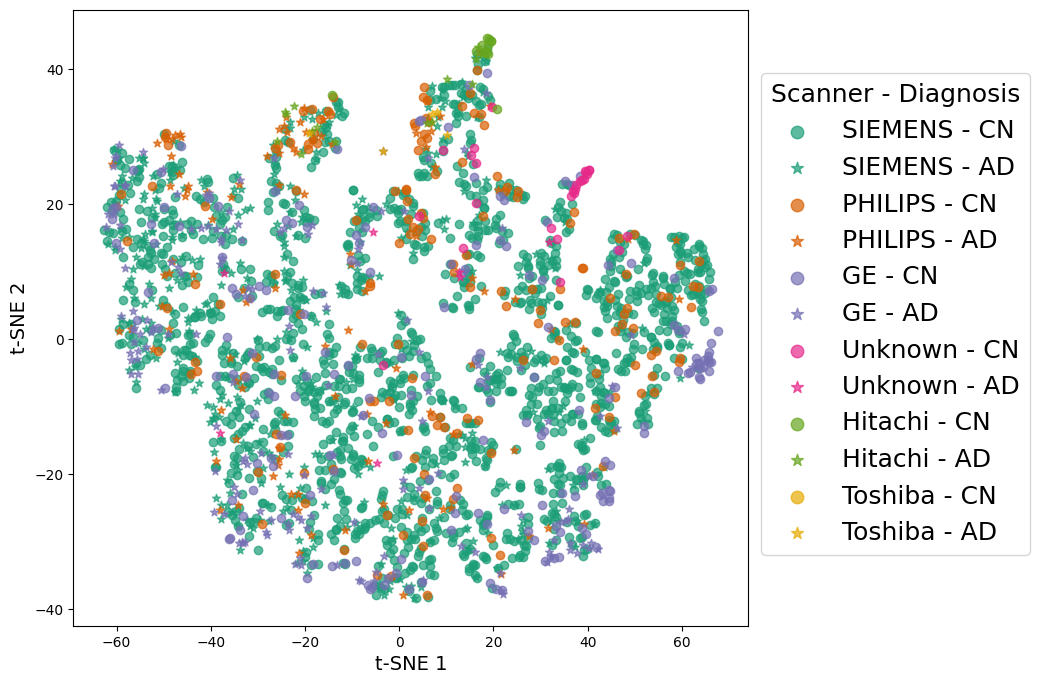

In [30]:
# ---------------------------
# Plot
# ---------------------------
scanners = df_sampled[scanner_col].unique()
labels = df_sampled[label_col].unique()
markers = {0: 'o', 1: '*'}  # CN: circle, AD: star

colors = cm.get_cmap('Dark2')
scanner_color = {scanner: colors(i) for i, scanner in enumerate(scanners)}

# Create a figure + single axes with fixed size
fig, ax = plt.subplots(figsize=(10, 8))

for scanner in scanners:
    for label in labels:
        subset = df_sampled[
            (df_sampled[scanner_col] == scanner) &
            (df_sampled[label_col] == label)
        ]
        ax.scatter(
            subset['tsne-1'], subset['tsne-2'],
            color=scanner_color[scanner],
            marker=markers[label],
            alpha=0.7,
            label=f"{scanner} - {'AD' if label == 1 else 'CN'}"
        )

# Remove duplicates
handles, labels_text = ax.get_legend_handles_labels()
unique = dict(zip(labels_text, handles))

# Create legend at figure level (NOT inside axes)
fig.legend(
    unique.values(), unique.keys(),
    bbox_to_anchor=(0.8, 0.5),
    title='Scanner - Diagnosis',
    title_fontsize=18,
    loc='center left',
    fontsize=18,
    markerscale=1.5
)

ax.set_xlabel("t-SNE 1", fontsize=14)
ax.set_ylabel("t-SNE 2", fontsize=14)

# Prevent the legend from changing axes size
plt.subplots_adjust(right=0.8)

# plt.savefig("tsne_brainiac_scanners_labels.png", dpi=300, bbox_inches='tight')
plt.show()


/tmp/ipykernel_282690/2520183181.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('Dark2')


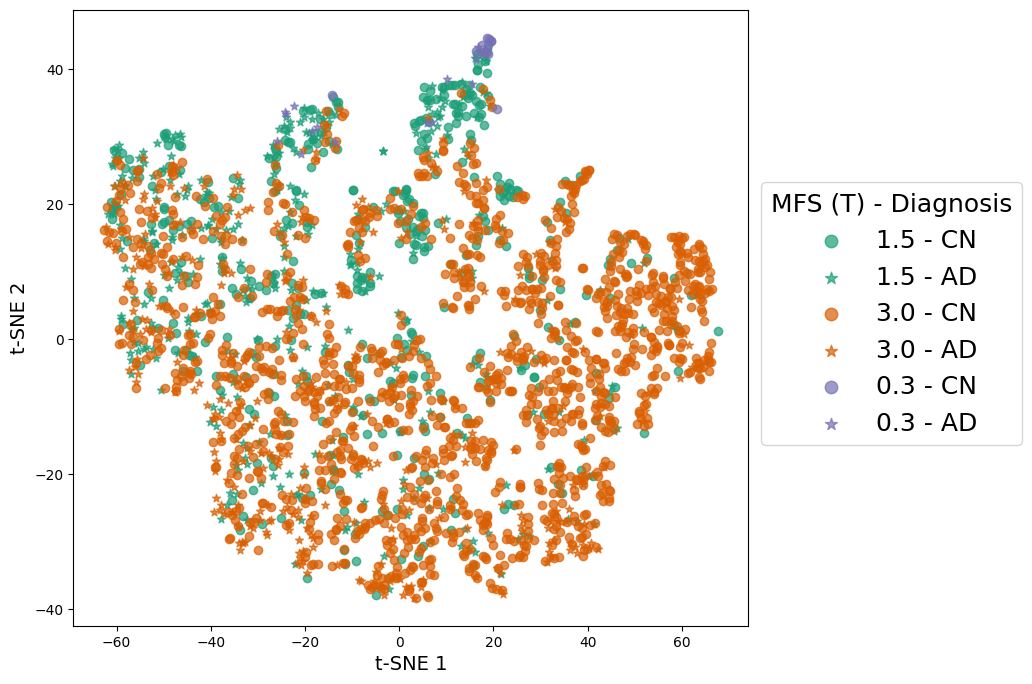

In [31]:
# ---------------------------
# Plot
# ---------------------------
mfs = df_sampled[mfs_col].unique()
labels = df_sampled[label_col].unique()
markers = {0: 'o', 1: '*'}  # CN: circle, AD: star

colors = cm.get_cmap('Dark2')
mfs_color = {mf: colors(i) for i, mf in enumerate(mfs)}

# Create a figure + single axes with fixed size
fig, ax = plt.subplots(figsize=(10, 8))

for mf in mfs:
    for label in labels:
        subset = df_sampled[
            (df_sampled[mfs_col] == mf) &
            (df_sampled[label_col] == label)
        ]
        ax.scatter(
            subset['tsne-1'], subset['tsne-2'],
            color=mfs_color[mf],
            marker=markers[label],
            alpha=0.7,
            label=f"{mf} - {'AD' if label == 1 else 'CN'}"
        )

# Remove duplicates
handles, labels_text = ax.get_legend_handles_labels()
unique = dict(zip(labels_text, handles))

# Create legend at figure level (NOT inside axes)
fig.legend(
    unique.values(), unique.keys(),
    bbox_to_anchor=(0.8, 0.5),
    title='MFS (T) - Diagnosis',
    title_fontsize=18,
    loc='center left',
    fontsize=18,
    markerscale=1.5
)

ax.set_xlabel("t-SNE 1", fontsize=14)
ax.set_ylabel("t-SNE 2", fontsize=14)

# Prevent the legend from changing axes size
plt.subplots_adjust(right=0.8)

# plt.savefig("tsne_brainiac_mfs_labels.png", dpi=300, bbox_inches='tight')
plt.show()


# Interactive 

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

def make_traces(color_col):
    fig = px.scatter(
        df_sampled,
        x="tsne-1",
        y="tsne-2",
        color=color_col,
        symbol=label_col,
        symbol_map={0: "circle", 1: "star"},
        hover_data={
            "id": True,
            cohort_col: True,
            scanner_col: True,
            mfs_col: True,
            label_col: True,
            "tsne-1": False,
            "tsne-2": False
        },
        opacity=0.7
    )

In [33]:
fig = px.scatter(
    df_sampled,
    x="tsne-1",
    y="tsne-2",
    color=cohort_col,               # default coloring
    symbol=label_col,
    symbol_map={0: "circle", 1: "star"},
    hover_data={
        "id": True,
        cohort_col: True,
        scanner_col: True,
        mfs_col: True,
        label_col: True,
        "tsne-1": False,
        "tsne-2": False
    },
    opacity=0.7,
    height=800,
    width=1000
)

fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="Color by cohort",
                    method="restyle",
                    args=["marker.color", [df_sampled[cohort_col]]]
                ),
                dict(
                    label="Color by scanner",
                    method="restyle",
                    args=["marker.color", [df_sampled[scanner_col]]]
                ),
                dict(
                    label="Color by field strength",
                    method="restyle",
                    args=["marker.color", [df_sampled[mfs_col]]]
                )
            ],
            direction="down",
            showactive=True,
            x=1.05,
            y=0.8
        )
    ],
    xaxis_title="t-SNE 1",
    yaxis_title="t-SNE 2",
    legend_title="Diagnosis"
)

# fig.write_html("tsne_interactive_sammed.html")


fig.show()
